# Data analysis
## Bissal Youssef - Lombardozzi Christian
### IUM project 2024/25

In [79]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.colors import ListedColormap
import plotly.graph_objects as go
import plotly.express as px


In [80]:

df_releases = pd.read_csv('../data/releases.csv')
df_genres = pd.read_csv('../data/genres.csv')
df_movies = pd.read_csv('../data/movies.csv')
df_studios = pd.read_csv('../data/studios.csv')
df_themes = pd.read_csv('../data/themes.csv')
df_countries = gpd.read_file('../data/countries.csv')
df_languages = pd.read_csv('../data/languages.csv')
df_posters = pd.read_csv('../data/posters.csv')
df_reviews = pd.read_csv('../data/rotten_tomatoes_reviews.csv')
df_crew = pd.read_csv('../data/crew.csv')
df_oscars = pd.read_csv('../data/the_oscar_awards.csv')
df_actors = pd.read_csv('../data/actors.csv')


In [81]:
df_actors['name'].duplicated()

0          False
1          False
2          False
3          False
4          False
           ...  
5798445     True
5798446    False
5798447     True
5798448     True
5798449     True
Name: name, Length: 5798450, dtype: bool

### Analysis n.1
* Is there any correlation between the rating of a movie and the number of oscars won by its actors after the release?

<Axes: xlabel='oscars_won', ylabel='rating'>

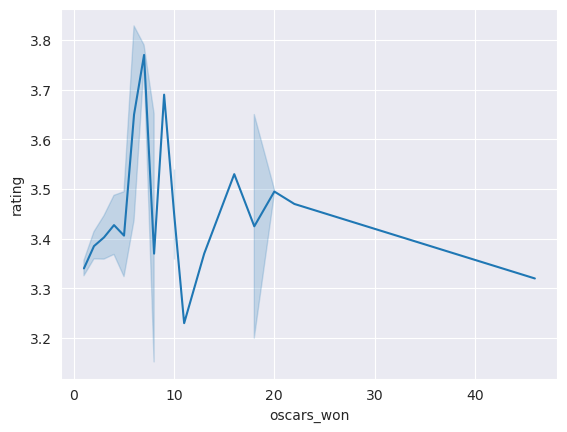

In [82]:

df_actors['name'] = df_actors['name'].astype(str)
df_oscars['name'] = df_oscars['name'].astype(str)

df_actors_oscar = df_oscars[(df_oscars['winner'] == True) &
                            (df_oscars['category'].isin(["ACTOR", "ACTRESS"]))]

df_actors_oscar = df_actors_oscar.merge(df_actors, on='name', how='inner')

df_actors_oscar = df_actors_oscar.merge(df_movies, on='id', how='inner')

df_actors_oscar = df_actors_oscar[df_actors_oscar['year_film'] <= df_actors_oscar['year_ceremony']]

df_actors_oscar_per_movie = df_actors_oscar.groupby('id').agg({'winner': 'count'}).reset_index()

df_actors_oscar_per_movie.columns = ['id', 'oscars_won']

df_actors_oscar_per_movie = df_actors_oscar_per_movie.merge(df_movies, on='id', how='inner')

df_actors_oscar_per_movie = df_actors_oscar_per_movie[['id', 'rating', 'oscars_won']]

sns.lineplot(data=df_actors_oscar_per_movie, x='oscars_won', y='rating')

### Analysis n.2
* Are the countries which produce more film translate a lot of films as well?

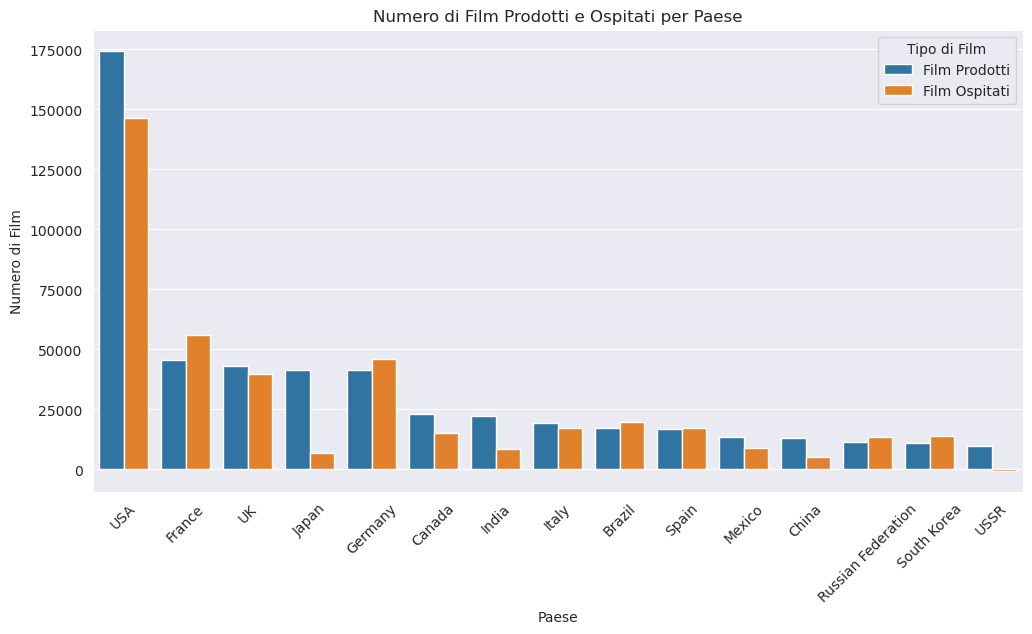

In [83]:

produced_films_per_country = df_countries['country'].value_counts().reset_index(name='produced_films')
produced_films_per_country.columns = ['country', 'produced_films']

hosted_films_per_country = df_releases['country'].value_counts().reset_index(name='hosted_films')
hosted_films_per_country.columns = ['country', 'hosted_films']

combined = pd.merge(produced_films_per_country, hosted_films_per_country, on='country', how='outer').fillna(0)

# Calcola i film ospitati esclusivamente (ossia film ospitati meno quelli prodotti)
combined['hosted_exclusively'] = combined['hosted_films'] - combined['produced_films']

top_countries = combined.nlargest(15, 'produced_films')

combined_melted = top_countries.melt(id_vars='country', value_vars=['produced_films', 'hosted_exclusively'],
                                     var_name='film_type', value_name='count')

combined_melted['film_type'] = combined_melted['film_type'].map({
    'produced_films': 'Film Prodotti',
    'hosted_exclusively': 'Film Ospitati'
})

plt.figure(figsize=(12, 6))
sns.barplot(data=combined_melted, x='country', y='count', hue='film_type')
plt.xlabel('Paese')
plt.ylabel('Numero di Film')
plt.title('Numero di Film Prodotti e Ospitati per Paese')
plt.xticks(rotation=45)
plt.legend(title='Tipo di Film')
plt.show()


### Analysis n.3
-

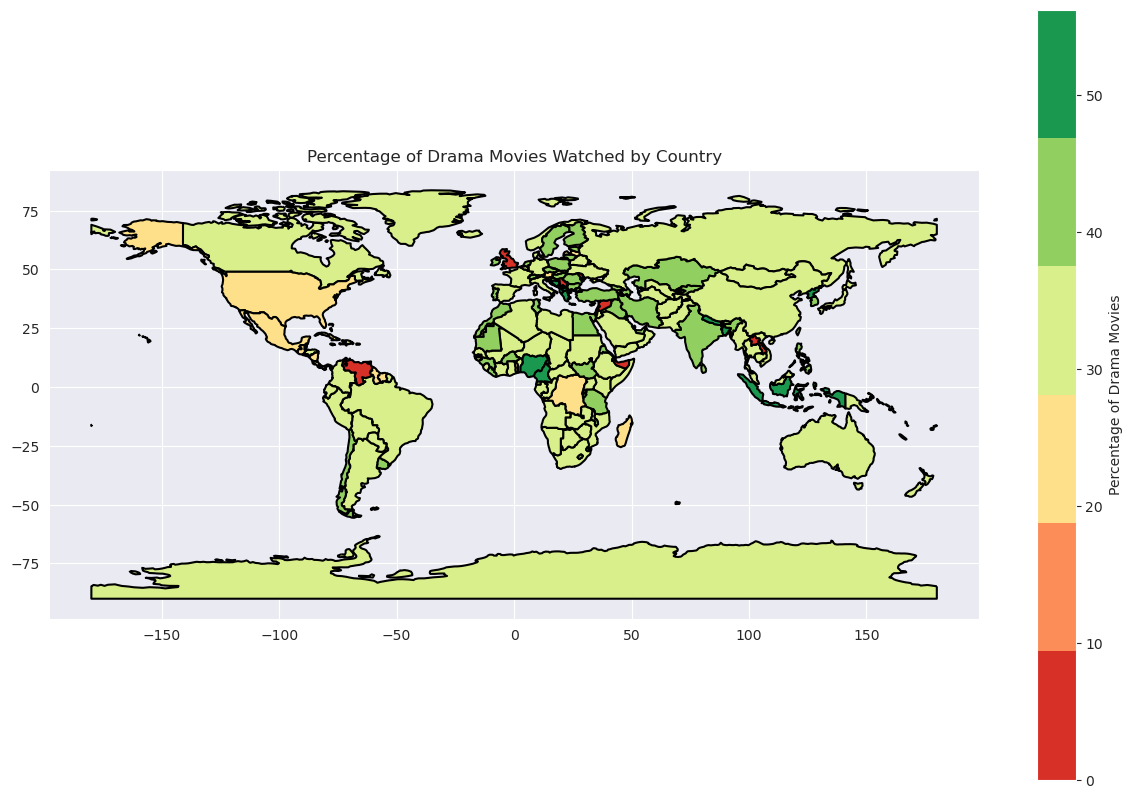

In [84]:

drama_movies = df_genres[df_genres['genre'] == 'Drama']

df_releases['country'] = df_releases['country'].replace({
    'US': 'United States of America',
    'USA': 'United States of America',
    'United States': 'United States of America',
    'Uk': 'United Kingdom',
    'Russian Federation': 'Russia',
    'Congo': 'Republic of the Congo',
    'Democratic Republic of Congo': 'Democratic Republic of the Congo',
})

df_countries['country'] = df_countries['country'].replace({
    'US': 'United States of America',
    'USA': 'United States of America',
    'United States': 'United States of America',
    'Uk': 'United Kingdom',
    'Russian Federation': 'Russia',
    'Congo': 'Republic of the Congo',
    'Democratic Republic of Congo': 'Democratic Republic of the Congo',
})

total_movies_per_country = df_releases['country'].value_counts().reset_index(name='total_movies_count')

drama_movies_per_country = df_releases.merge(drama_movies, on='id', how='inner')
drama_movies_per_country = drama_movies_per_country['country'].value_counts().reset_index(name='drama_movies_count')

combined = pd.merge(drama_movies_per_country, total_movies_per_country, on='country', how='inner')
combined.columns = ['country', 'drama_movies_count', 'total_movies_count']

# Calculate the percentage of drama movies
combined['drama_percentage'] = (combined['drama_movies_count'] / combined['total_movies_count']) * 100

world = gpd.read_file('https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip')

world_data_gdf = world.merge(combined, how='left', left_on='SOVEREIGNT', right_on='country')

world_data_gdf['drama_percentage'] = world_data_gdf['drama_percentage'].fillna(0)

colors = ['#d73027', '#fc8d59', '#fee08b', '#d9ef8b', '#91cf60', '#1a9850']
cmap = ListedColormap(colors)

world_data_gdf.plot(figsize=(15, 10), edgecolor='black', linewidth=1.5, column='drama_percentage', legend=True,
                    cmap=cmap, legend_kwds={'label': "Percentage of Drama Movies"})
plt.title('Percentage of Drama Movies Watched by Country')
plt.show()

### Analysis n.4
## 3d visualizations for rating, oscars won in time
- getting the right dataframe

In [85]:
df_movies_partial = df_movies[['id', 'date', 'name']]
df_actors_oscar_per_movie = df_actors_oscar_per_movie.merge(df_movies_partial, on='id', how='inner')
df_actors_oscar_per_movie.head()

,id,rating,oscars_won,date,name
0,1000007,4.35,1,2014.0,Interstellar
1,1000021,4.45,1,2023.0,Spider-Man: Across the Spider-Verse
2,1000034,4.24,1,1980.0,The Shining
3,1000046,4.55,2,1972.0,The Godfather
4,1000082,4.17,1,1977.0,Star Wars


In [86]:
df_actors_oscar_per_movie.sort_values(by='oscars_won', ascending=False, inplace=True)
df_actors_oscar_per_movie.head()

,id,rating,oscars_won,date,name
1141,1021431,3.32,46,2014.0,And the Oscar Goes To...
3701,1112306,NaN,31,1940.0,Cavalcade of the Academy Awards
2468,1058048,NaN,25,1975.0,"Brother, Can You Spare a Dime?"
4168,1141796,NaN,24,1972.0,Hollywood: The Dream Factory
4870,1198680,NaN,24,1961.0,Hollywood: The Selznick Years


- now we'll display the 3d plot


In [87]:

fig = go.Figure(data=[go.Scatter3d(
    x=df_actors_oscar_per_movie['date'],
    y=df_actors_oscar_per_movie['rating'],
    z=df_actors_oscar_per_movie['oscars_won'],
    mode='markers',
    text=[
        f"{name}<br>Rating: {rating}<br>Oscars: {oscars}<br>Date: {int(date) if not pd.isna(date) else 'N/A'}"
        for name, rating, oscars, date in zip(
            df_actors_oscar_per_movie['name'],
            df_actors_oscar_per_movie['rating'],
            df_actors_oscar_per_movie['oscars_won'],
            df_actors_oscar_per_movie['date']
        )
    ],
    hoverinfo='text',
    marker=dict(
        size=6,
        color=df_actors_oscar_per_movie['rating'],
        colorscale= 'viridis',
        opacity=0.8
    )
)])

fig.update_layout(
    scene=dict(
        xaxis_title='Date',
        yaxis_title='Rating',
        zaxis_title='Oscars Won'
    ),
    title='3D Scatter Plot - Rating vs Oscars vs Date'
)

fig.show()


### Analysis n.5
## Number of reviews vs rating
- we need to filtrate from movies, only the film without duplicated names


In [88]:
df_nodup_movies = df_movies[['id', 'date', 'name', 'rating']]
df_nodup_movies = df_nodup_movies[~df_nodup_movies['name'].duplicated(keep=False)]

- now group the reviews by the name of the movie

In [89]:
df_grouped_reviews = df_reviews.groupby(['rotten_tomatoes_link','movie_title'])['review_date'].count().reset_index()
df_grouped_reviews.rename(columns={'movie_title':'name', 'review_date':'number_of_reviews'}, inplace=True)
df_grouped_reviews.head()

,rotten_tomatoes_link,name,number_of_reviews
0,m/0814255,Percy Jackson & the Olympians: The Lightning T...,149
1,m/0878835,Please Give,142
2,m/10,10,24
3,m/1000013-12_angry_men,12 Angry Men (Twelve Angry Men),54
4,m/1000079-20000_leagues_under_the_sea,"20,000 Leagues Under The Sea",27


- now merge the dataframes

In [90]:
df_merged_reviews_movies = df_grouped_reviews.merge(df_nodup_movies, on='name', how='left')
print("shape[0]", df_merged_reviews_movies.shape[0])
print("number of nulll: ", df_merged_reviews_movies['rating'].isna().sum())
df_merged_reviews_movies.head(15)

shape[0] 17706
number of nulll:  9841


,rotten_tomatoes_link,name,number_of_reviews,id,date,rating
0,m/0814255,Percy Jackson & the Olympians: The Lightning T...,149,1001163.0,2010.0,2.56
1,m/0878835,Please Give,142,1016145.0,2010.0,3.46
2,m/10,10,24,NaN,NaN,NaN
3,m/1000013-12_angry_men,12 Angry Men (Twelve Angry Men),54,NaN,NaN,NaN
4,m/1000079-20000_leagues_under_the_sea,"20,000 Leagues Under The Sea",27,NaN,NaN,NaN
5,m/10000_bc,"10,000 B.C.",149,NaN,NaN,NaN
6,m/1000121-39_steps,The 39 Steps,51,NaN,NaN,NaN
7,m/1000123-310_to_yuma,3:10 to Yuma,28,NaN,NaN,NaN
8,m/10002008-charly,Charly (A Heartbeat Away),10,NaN,NaN,NaN
9,m/1000204-abraham_lincoln,Abraham Lincoln,11,NaN,NaN,NaN


- cleaning the NaN data

In [91]:
df_merged_reviews_movies = df_merged_reviews_movies.dropna(subset=['rating'],  how='any')
df_merged_reviews_movies.head()

,rotten_tomatoes_link,name,number_of_reviews,id,date,rating
0,m/0814255,Percy Jackson & the Olympians: The Lightning T...,149,1001163.0,2010.0,2.56
1,m/0878835,Please Give,142,1016145.0,2010.0,3.46
20,m/1000355-adventures_of_robin_hood,The Adventures of Robin Hood,48,1004574.0,1938.0,3.85
36,m/10004890-narrow_margin,The Narrow Margin,11,1013283.0,1952.0,3.81
40,m/10005178-saint_ralph,Saint Ralph,69,1051925.0,2004.0,3.39


- heatmap with correlation matrix

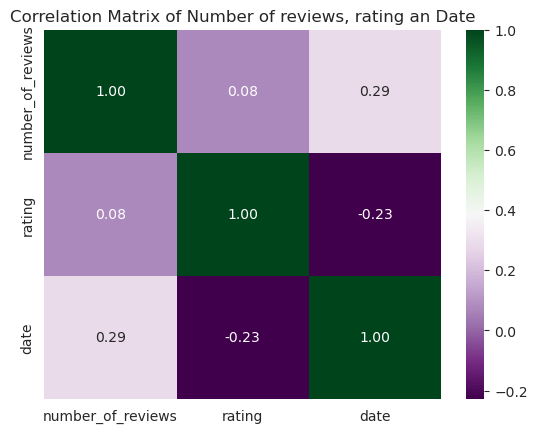

In [92]:
correlation_matrix = df_merged_reviews_movies[['number_of_reviews','rating', 'date']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap= 'PRGn', fmt='.2f')
plt.title('Correlation Matrix of Number of reviews, rating an Date')
plt.show()

### Analysis n.6
## Average rating vs Number of Reviews per year


In [93]:
df_summary = df_merged_reviews_movies.groupby('date').agg({
    'rating':'mean',
    'number_of_reviews':'sum'
}).reset_index()
df_summary.head()


,date,rating,number_of_reviews
0,1914.0,3.510000,26
1,1920.0,3.070000,12
2,1921.0,3.550000,13
3,1922.0,3.570000,30
4,1923.0,3.816667,110


In [94]:
fig = go.Figure()

#first line
fig.add_trace(go.Scatter(
    x=df_summary['date'],
    y=df_summary['rating'],
    mode='lines+markers',
    name='Average Rating',
    line=dict(color='royalblue')
))

#second line
fig.add_trace(go.Scatter(
    x=df_summary['date'],
    y=df_summary['number_of_reviews'],
    mode='lines+markers',
    name='Number of Reviews',
    yaxis='y2',
    line=dict(color='firebrick')
))

# double y axe
fig.update_layout(
    title='Mean rating vs number of reviews per year',
    xaxis=dict(title='Year'),
    yaxis=dict(title='Average Rating', side='left'),
    yaxis2=dict(
        title='Number of Reviews',
        overlaying='y',
        side='right'
    ),
    legend=dict(x=0.1, y=1.1, orientation='h')
)

fig.show()

### Analysis n.7
## Homonymus among actors and the role they have played
- first modify the actors dataframe to divide name and surname


In [95]:
df_actors['first_name'] = df_actors['name'].apply(lambda x: x.split()[0])
df_actors['last_name'] = df_actors['name'].apply(lambda x: ' '.join(x.split()[1:]) if len(x.split()) > 1 else '')
df_actors.head()

,id,name,role,first_name,last_name
0,1000001,Margot Robbie,Barbie,Margot,Robbie
1,1000001,Ryan Gosling,Ken,Ryan,Gosling
2,1000001,America Ferrera,Gloria,America,Ferrera
3,1000001,Ariana Greenblatt,Sasha,Ariana,Greenblatt
4,1000001,Issa Rae,Barbie,Issa,Rae


- obtaining all the actors that have played Homonymus role

In [96]:
df_actors_homonymus = df_actors[df_actors['first_name'].str.lower() == df_actors['role'].str.lower()]
print("numer of actors:", len(df_actors))
print("number of homonymus:", len(df_actors_homonymus))
print(f"percentage of homonymus:{100*len(df_actors_homonymus)/len(df_actors) :.2f}%")
df_actors_homonymus.head()

numer of actors: 5798450
number of homonymus: 46386
percentage of homonymus:0.80%


,id,name,role,first_name,last_name
347,1000005,Josh Pence,Josh,Josh,Pence
775,1000010,Paul Calderon,Paul,Paul,Calderon
1502,1000022,Ron Taylor,Ron,Ron,Taylor
1503,1000022,Don Taylor,Don,Don,Taylor
2362,1000033,Gillian M. Berrow,Gillian,Gillian,M. Berrow


- Counting the number of homonymus actors group by the name

In [97]:
name_counts = df_actors_homonymus['first_name'].value_counts().reset_index()
name_counts.columns = ['name', 'count']
name_counts.sort_values('count', ascending=False, inplace=True)
name_counts.head()

,name,count
0,David,287
1,Michael,261
2,John,246
3,Larry,228
4,Joe,220


- display with a bubble plot

In [98]:
fig = px.scatter(
    name_counts, x='name', y='count', size='count',
    color='count', title='Names equal to their role (Homonymus)',
    labels={'count': 'Occurrences'}
)
fig.show()

- a Zoom on the fist 1000 names

In [99]:
fig = px.scatter(
    name_counts.head(1000), x='name', y='count', size='count',
    color='count', title='Names equal to their role (Homonymus)',
    labels={'count': 'Occurrences'}
)
fig.show()